# Oxford-IIIT Pet: მონაცემების ანალიზი (EDA)

წინამდებარე ანალიზი ეფუძნება მხოლოდ trainval.txt ნაკრებს (3,680 სურათი). test.txt ფაილს კი სრულიად ხელუხლებლად ვინახავთ და მხოლოდ საბოლოო შეფასებისთვის გამოვიყენებთ.

In [1]:
import os
import sys
import random
from pathlib import Path

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from PIL import Image

ROOT = Path.cwd() if (Path.cwd() / 'src').exists() else Path.cwd().parent
os.chdir(ROOT)
sys.path.insert(0, str(ROOT))

DATA_ROOT = Path('data') / 'oxford-iiit-pet'
IMAGES_DIR = DATA_ROOT / 'images'
MASKS_DIR = DATA_ROOT / 'annotations' / 'trimaps'
TRAINVAL_FILE = DATA_ROOT / 'annotations' / 'trainval.txt'

SEED = 42

## 1. trainval.txt-ის წაკითხვა

ფორმატი: `IMAGE_NAME CLASS_ID SPECIES BREED_ID`, სადაც `SPECIES`: 1 = Cat, 2 = Dog.
ჯიშის სახელი ფაილის სახელიდან მოდის (`Egyptian_Mau_14` → `Egyptian_Mau`). კატის ჯიშები დიდი ასოთი იწყება, ძაღლისა — პატარათი.

In [2]:
df = pd.read_csv(TRAINVAL_FILE, sep=' ', header=None,
                 names=['name', 'class_id', 'species', 'breed_id'])
df['species'] = df['species'].map({1: 'Cat', 2: 'Dog'})
df['breed'] = df['name'].str.rsplit('_', n=1).str[0]
df['image_path'] = df['name'].map(lambda n: str(IMAGES_DIR / f'{n}.jpg'))
df['mask_path'] = df['name'].map(lambda n: str(MASKS_DIR / f'{n}.png'))

missing = [p for p in pd.concat([df['image_path'], df['mask_path']]) if not os.path.exists(p)]

print(f"total trainval images: {len(df)}")
print(f"number of breeds: {df['breed'].nunique()}")
print(f"missing files: {len(missing)}")
df.head()

total trainval images: 3680
number of breeds: 37
missing files: 0


,name,class_id,species,breed_id,breed,image_path,mask_path
0,Abyssinian_100,1,Cat,1,Abyssinian,data\oxford-iiit-pet\images\Abyssinian_100.jpg,data\oxford-iiit-pet\annotations\trimaps\Abyss...
1,Abyssinian_101,1,Cat,1,Abyssinian,data\oxford-iiit-pet\images\Abyssinian_101.jpg,data\oxford-iiit-pet\annotations\trimaps\Abyss...
2,Abyssinian_102,1,Cat,1,Abyssinian,data\oxford-iiit-pet\images\Abyssinian_102.jpg,data\oxford-iiit-pet\annotations\trimaps\Abyss...
3,Abyssinian_103,1,Cat,1,Abyssinian,data\oxford-iiit-pet\images\Abyssinian_103.jpg,data\oxford-iiit-pet\annotations\trimaps\Abyss...
4,Abyssinian_104,1,Cat,1,Abyssinian,data\oxford-iiit-pet\images\Abyssinian_104.jpg,data\oxford-iiit-pet\annotations\trimaps\Abyss...


## 2. მაგალითები: სურათი, Trimap ნიღაბი, Overlay

Trimap მნიშვნელობები: `1` = ცხოველი, `2` = ფონი, `3` = საზღვარი (Not classified).
`vmin=1, vmax=3` უზრუნველყოფს, რომ ფერი ყველა ნიღაბზე ერთსა და იმავე კლასს შეესაბამებოდეს.

unique values of mask: [1 2 3]


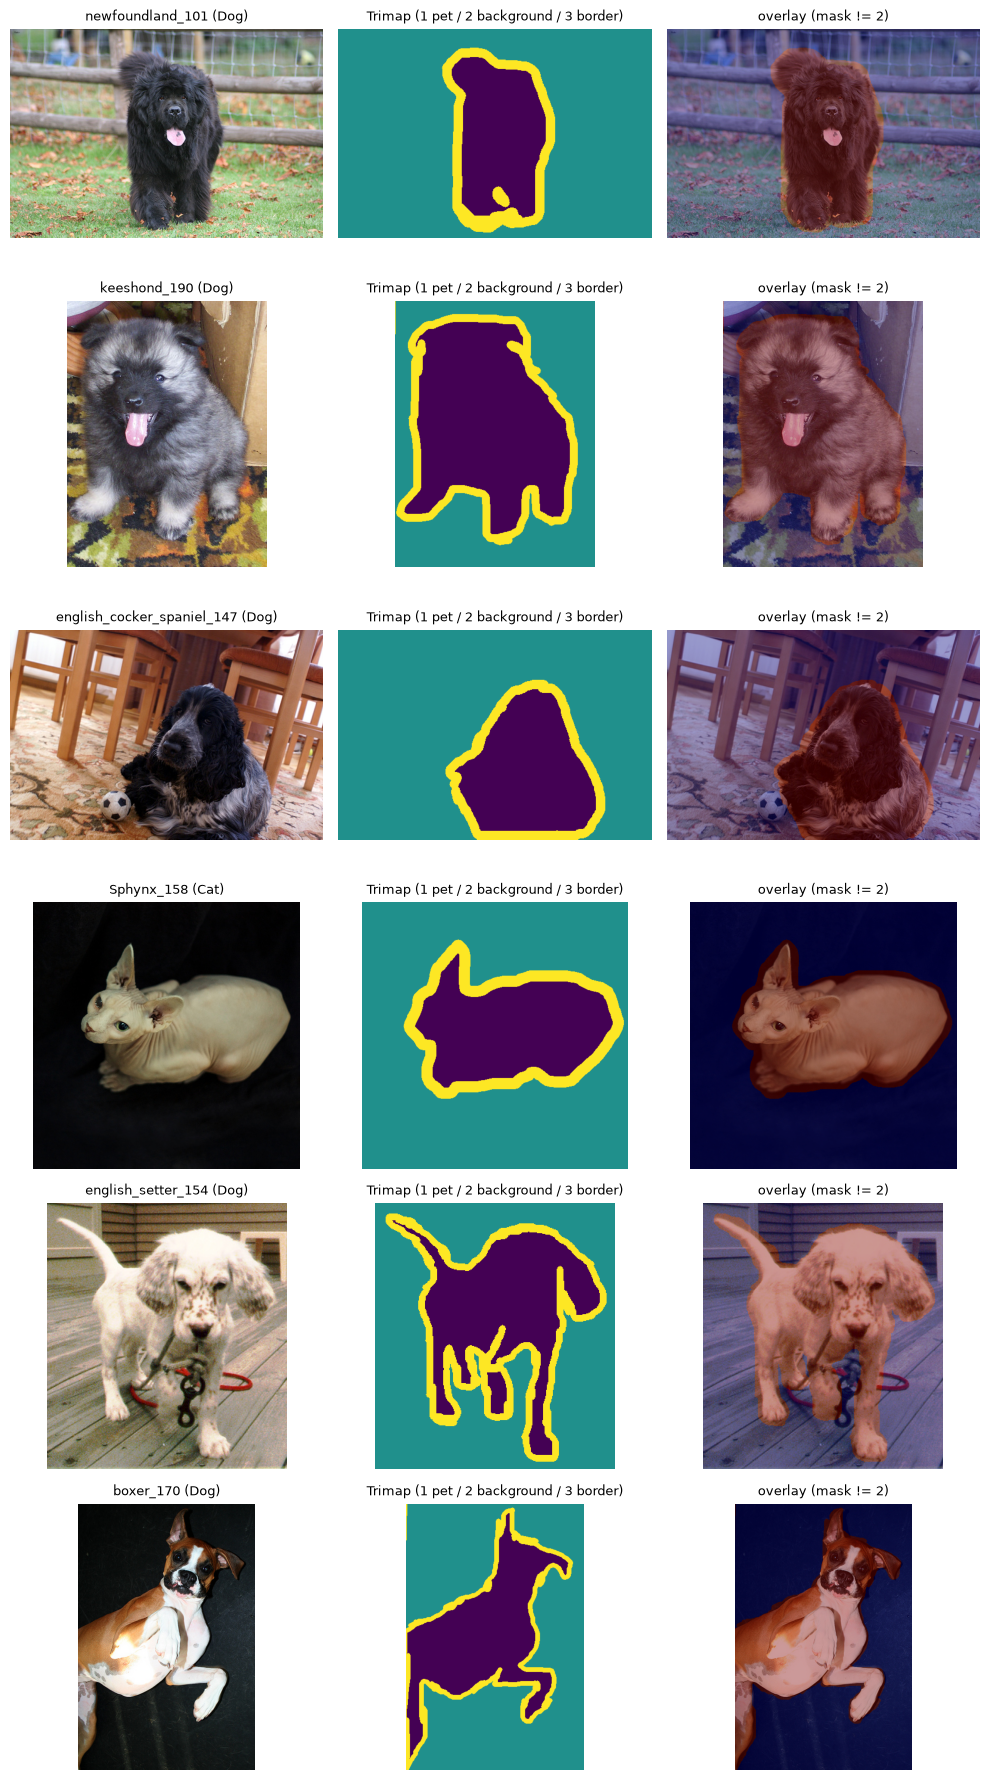

In [3]:
sample = df.sample(6, random_state=SEED)

print("unique values of mask:",
      np.unique(cv2.imread(sample['mask_path'].iloc[0], cv2.IMREAD_UNCHANGED)))

fig, axes = plt.subplots(6, 3, figsize=(10, 18))
for i, row in enumerate(sample.itertuples()):
    img = cv2.cvtColor(cv2.imread(row.image_path), cv2.COLOR_BGR2RGB)
    mask = cv2.imread(row.mask_path, cv2.IMREAD_UNCHANGED)

    axes[i, 0].imshow(img)
    axes[i, 0].set_title(f'{row.name} ({row.species})', fontsize=9)
    axes[i, 1].imshow(mask, vmin=1, vmax=3)
    axes[i, 1].set_title('Trimap (1 pet / 2 background / 3 border)', fontsize=9)
    axes[i, 2].imshow(img)
    axes[i, 2].imshow(mask != 2, alpha=0.4, cmap='jet')
    axes[i, 2].set_title('overlay (mask != 2)', fontsize=9)
    for ax in axes[i]:
        ax.axis('off')

plt.tight_layout()
plt.show()

## 3. სურათების ზომები, Aspect Ratio და რეჟიმები

         width   height   aspect
count  3680.00  3680.00  3680.00
mean    431.03   383.42     1.18
std     126.33   116.83     0.32
min     114.00   108.00     0.52
25%     333.00   333.00     0.78
50%     500.00   375.00     1.33
75%     500.00   500.00     1.46
max    3264.00  2606.00     2.56

image options: {'RGB': 3678, 'RGBA': 2}
non-rgb images: ['Egyptian_Mau_14', 'Egyptian_Mau_186']


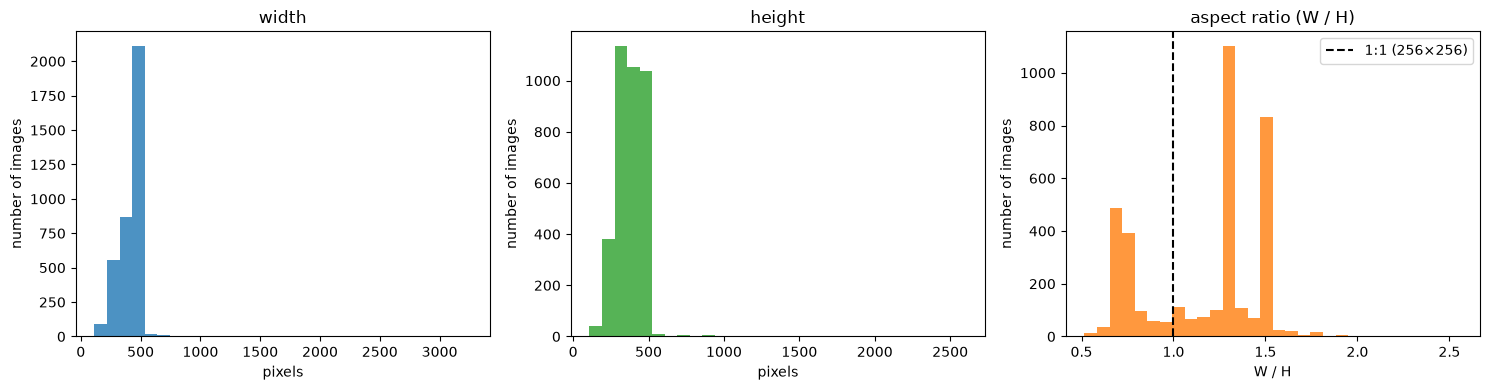

In [4]:
widths, heights, modes = [], [], []
for path in df['image_path']:
    with Image.open(path) as img:
        widths.append(img.width)
        heights.append(img.height)
        modes.append(img.mode)

df['width'] = widths
df['height'] = heights
df['aspect'] = df['width'] / df['height']
df['mode'] = modes

print(df[['width', 'height', 'aspect']].describe().round(2))
print("\nimage options:", df['mode'].value_counts().to_dict())
print("non-rgb images:", df.loc[df['mode'] != 'RGB', 'name'].tolist())

fig, ax = plt.subplots(1, 3, figsize=(15, 4))
ax[0].hist(df['width'], bins=30, color='tab:blue', alpha=0.8)
ax[0].set(title='width', xlabel='pixels', ylabel='number of images')
ax[1].hist(df['height'], bins=30, color='tab:green', alpha=0.8)
ax[1].set(title='height', xlabel='pixels', ylabel='number of images')
ax[2].hist(df['aspect'], bins=30, color='tab:orange', alpha=0.8)
ax[2].axvline(1.0, color='black', linestyle='--', label='1:1 (256×256)')
ax[2].set(title='aspect ratio (W / H)', xlabel='W / H', ylabel='number of images')
ax[2].legend()
plt.tight_layout()
plt.show()

## 4. კლასების ბალანსი: სახეობა და ჯიში

Dog: 2492 (67.7%)
Cat: 1188 (32.3%)

images per breed: min 93, max 100, median 100


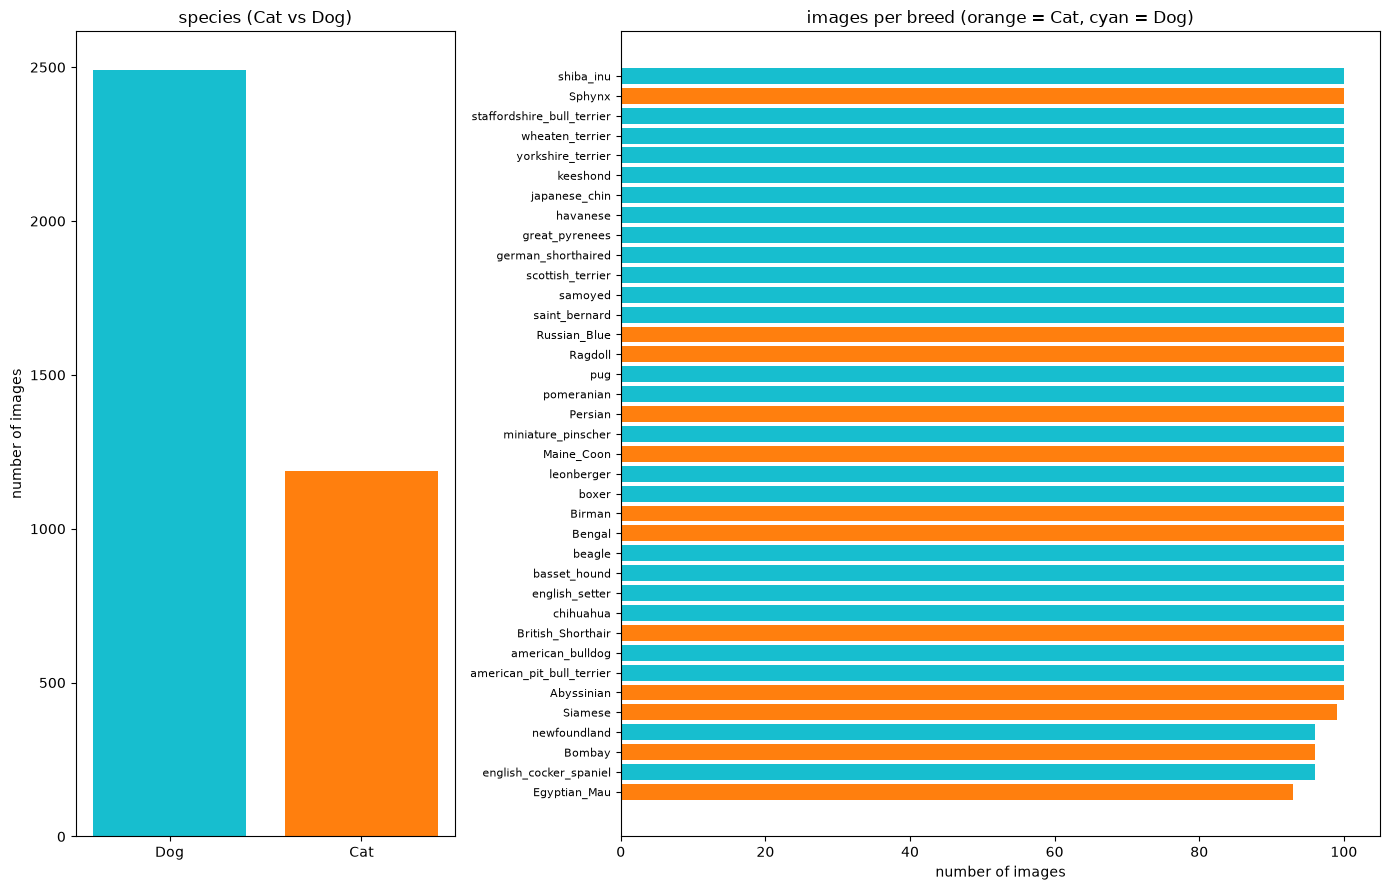

In [5]:
species_counts = df['species'].value_counts()
breed_counts = df['breed'].value_counts().sort_values()
breed_species = df.drop_duplicates('breed').set_index('breed')['species']

for s, c in species_counts.items():
    print(f"{s}: {c} ({c / len(df) * 100:.1f}%)")
print(f"\nimages per breed: min {breed_counts.min()}, max {breed_counts.max()}, "
      f"median {breed_counts.median():.0f}")

fig, ax = plt.subplots(1, 2, figsize=(14, 9), gridspec_kw={'width_ratios': [1, 2]})
ax[0].bar(species_counts.index, species_counts.values,
          color=['tab:cyan' if s == 'Dog' else 'tab:orange' for s in species_counts.index])
ax[0].set(title='species (Cat vs Dog)', ylabel='number of images')
ax[1].barh(breed_counts.index, breed_counts.values,
           color=['tab:orange' if breed_species[b] == 'Cat' else 'tab:cyan' for b in breed_counts.index])
ax[1].set(title='images per breed (orange = Cat, cyan = Dog)',
          xlabel='number of images')
ax[1].tick_params(axis='y', labelsize=8)
plt.tight_layout()
plt.show()

## 5. ცხოველის ფართობი სურათში

ორი განსაზღვრება: მხოლოდ ცხოველი (`mask == 1`) და ცხოველი + საზღვარი (`mask != 2`).
მოდელი მეორეს იყენებს (`src/data/dataset.py`).

pet only (mask == 1): 29.96%
pet + border (mask != 2): 41.36%
share added by border: 11.40%
background (mask == 2): 58.64%

masks with pet < 1%: 7
                 name  pet_only  pet_with_border
    saint_bernard_108       0.0              0.0
     Egyptian_Mau_162       0.0              0.0
     Egyptian_Mau_165       0.0              0.0
     Egyptian_Mau_196       0.0              0.0
        leonberger_18       0.0              0.0
miniature_pinscher_14       0.0              0.0
     saint_bernard_15       0.0              0.0


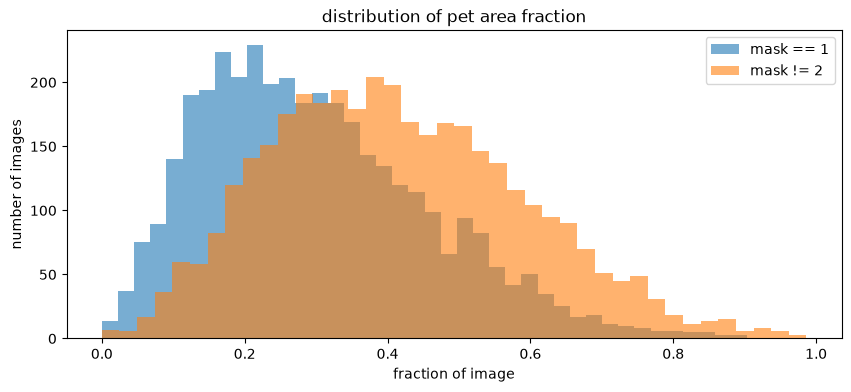

In [6]:
pet_only, pet_with_border = [], []
for path in df['mask_path']:
    mask = cv2.imread(path, cv2.IMREAD_UNCHANGED)
    pet_only.append(np.mean(mask == 1))
    pet_with_border.append(np.mean(mask != 2))

df['pet_only'] = pet_only
df['pet_with_border'] = pet_with_border

print(f"pet only (mask == 1): {df['pet_only'].mean() * 100:.2f}%")
print(f"pet + border (mask != 2): {df['pet_with_border'].mean() * 100:.2f}%")
print(f"share added by border: {(df['pet_with_border'] - df['pet_only']).mean() * 100:.2f}%")
print(f"background (mask == 2): {(1 - df['pet_with_border'].mean()) * 100:.2f}%")

near_empty = df[df['pet_only'] < 0.01]
print(f"\nmasks with pet < 1%: {len(near_empty)}")
print(near_empty[['name', 'pet_only', 'pet_with_border']].round(4).to_string(index=False))

plt.figure(figsize=(10, 4))
plt.hist(df['pet_only'], bins=40, alpha=0.6, label='mask == 1')
plt.hist(df['pet_with_border'], bins=40, alpha=0.6, label='mask != 2')
plt.title('distribution of pet area fraction')
plt.xlabel('fraction of image')
plt.ylabel('number of images')
plt.legend()
plt.show()

## 6. PetDataset-ის შემოწმება

In [7]:
from src.dataset import get_splits

train_dataset, val_dataset = get_splits(str(DATA_ROOT), val_size=0.15, seed=SEED, img_size=256)

sample_img, sample_mask = train_dataset[0]

print(f"train: {len(train_dataset)}, val: {len(val_dataset)}, total: {len(train_dataset) + len(val_dataset)}")
print("image tensor shape:", sample_img.shape)
print("mask tensor shape:", sample_mask.shape)
print("mask unique values:", torch.unique(sample_mask))

empty masks removed: 7
train: 3122, val: 551, total: 3673
image tensor shape: torch.Size([3, 256, 256])
mask tensor shape: torch.Size([1, 256, 256])
mask unique values: tensor([0., 1.])


## EDA დასკვნები (Exploratory Data Analysis Summary)

* მონაცემთა რაოდენობა და ბალანსი:** `trainval.txt` შეიცავს 3,680 სურათს: 1,188 კატა (32.3%) და 2,492 ძაღლი (67.7%). სახეობების დონეზე მონაცემები არაა დაბალანსებული (ძაღლი ~2-ჯერ მეტია), თუმცა 37 ჯიშიდან თითოეულზე მოდის 93–100 სურათი, ანუ ჯიშების მიხედვით ბალანსი კარგია.
* სურათების ზომები და ფორმატი:** სურათები განსხვავებული რეზოლუციისაა (სიგანე 114–3264, სიმაღლე 108–2606 პიქსელი; მედიანა 500×375), ამიტომ ყველა სურათი 256×256-ზე იცვლება. Aspect ratio-ს (W/H) მედიანა 1.33-ია, დიაპაზონი 0.52–2.56: 256×256-ზე resize სურათებს ოდნავ ჭყლეტს, თუმცა ნიღაბი ზუსტად ისევე იჭყლიტება, ამიტომ ეს მისაღებია. 3,680 სურათიდან 3,678 არის RGB, ხოლო 2 (`Egyptian_Mau_14`, `Egyptian_Mau_186`) — RGBA; `cv2.imread` მათ 3-არხიან BGR-ად კითხულობს.
* სეგმენტაციის ფართობი:** უშუალოდ ცხოველი (`mask == 1`) სურათის საშუალოდ 29.96%-ს იკავებს, საზღვრის დამატებით (`mask != 2`) — 41.36%-ს; საზღვარი დამატებით 11.40%-ს შეადგენს. 7 ნიღაბში ცხოველის წილი 1%-ზე ნაკლებია (სექცია 5) — ეს სავარაუდოდ ანოტაციის შეცდომებია და სასწავლო მონაცემებიდან გაიფილტრა.
* საზღვრის დამუშავება:** ბინარული სეგმენტაციისთვის საზღვარი (`3`) მივაკუთვნეთ დადებით კლასს (`mask != 2`), რადგან კონტური უშუალოდ ცხოველის სხეულის კიდეს წარმოადგენს და მისი გამოტოვება მოდელს ობიექტის ფორმის სწორად აღქმაში შეუშლიდა ხელს.
* მეტრიკების არჩევანი:** სურათის უმეტესი ნაწილი (~59%) ფონია, ამიტომ Pixel Accuracy შეცდომაში შემყვანია (მოდელი, რომელიც მხოლოდ ფონს წინასწარმეტყველებს, მაინც ~59%-ს აჩვენებს). მოდელის შეფასებისთვის გამოვიყენებთ **IoU (Intersection over Union)** და **Dice Coefficient** მეტრიკებს.

In [8]:
from src.model import build_model
import torch

model = build_model(encoder_name="resnet18", encoder_weights="imagenet")

dummy_input = torch.randn(2, 3, 256, 256)
outputs = model(dummy_input)

print("output shape:", outputs.shape) 

TypeError: build_model() got an unexpected keyword argument 'encoder_name'